# 03 - Exploratory Data Analysis
Each chart is followed by one business takeaway. Plot code lives in `src/eda.py`.

In [1]:
import sys; sys.path.append('..')
from src import eda
df = eda.load(); df.shape

(7043, 23)

## 1. Tenure vs churn

In [2]:
eda.fig_tenure(df)

Churn
0    38.0
1    10.0
Name: tenure, dtype: float64

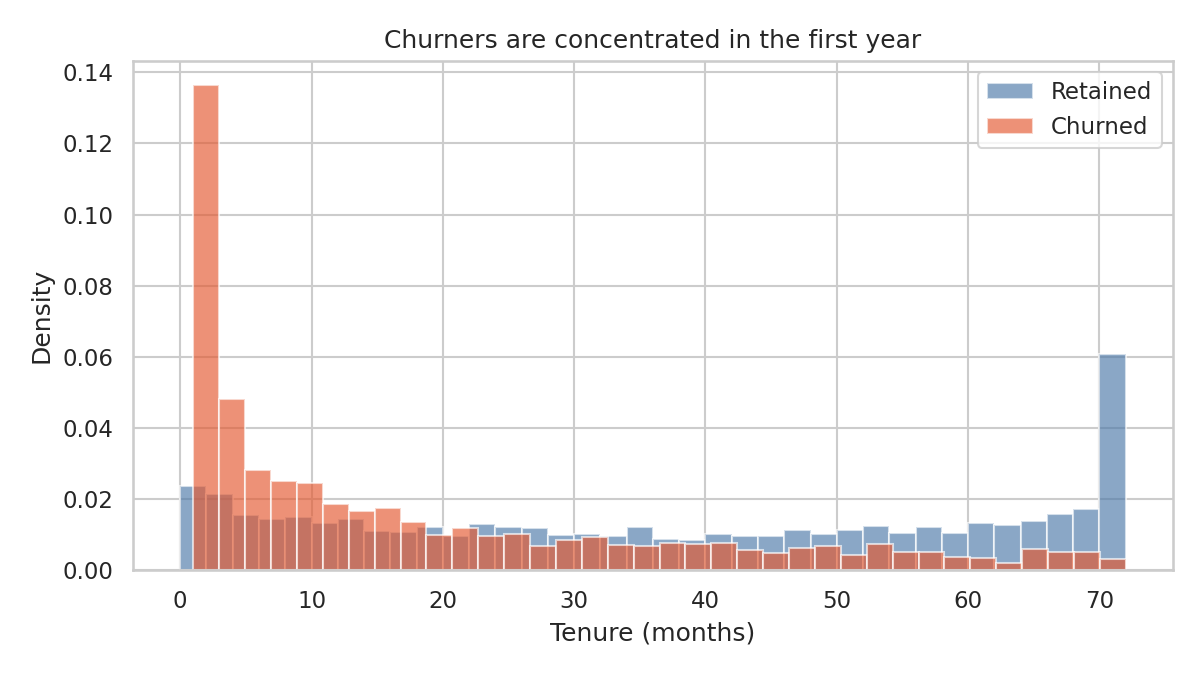

In [3]:
from IPython.display import Image; Image('../reports/figures/01_tenure_by_churn.png')

**Takeaway:** median tenure is **10 months for churners vs 38 for retained customers**. The first year is where retention is won or lost, so onboarding is the highest-leverage intervention window.

## 2. Monthly charges vs churn

In [4]:
eda.fig_monthly(df)

Churn
0    64.425
1    79.650
Name: MonthlyCharges, dtype: float64

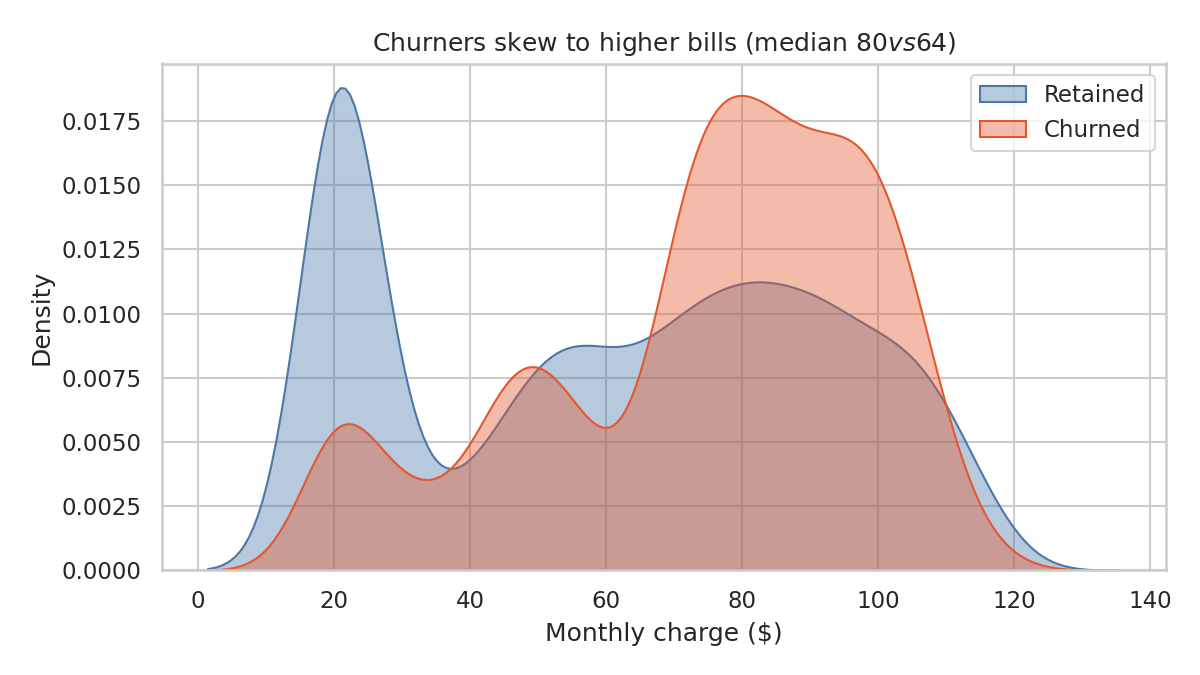

In [5]:
from IPython.display import Image; Image('../reports/figures/02_monthly_charges_by_churn.png')

**Takeaway:** churners pay more (median **$80 vs $64**). Price alone is not the driver (the cheapest, no-internet customers stay), but higher bills raise churn when paired with no commitment or weak product attachment.

## 3. Contract type

In [6]:
eda.fig_contract(df)

Contract
Month-to-month    42.7
One year          11.3
Two year           2.8
Name: mean, dtype: float64

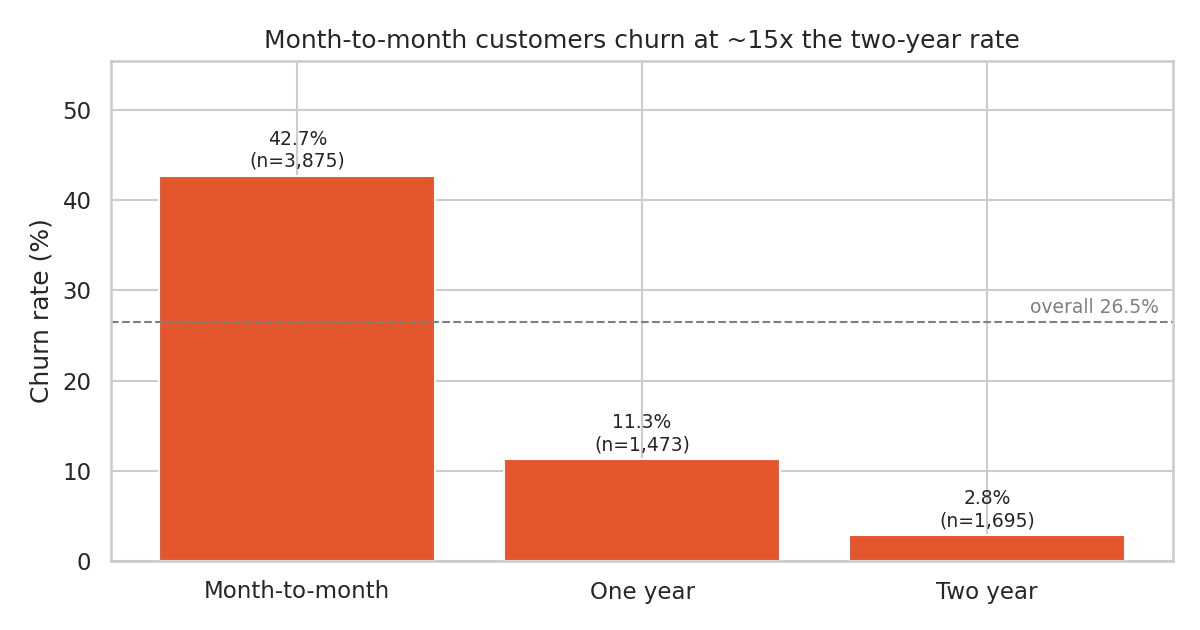

In [7]:
from IPython.display import Image; Image('../reports/figures/03_churn_by_contract.png')

**Takeaway:** month-to-month churn is **42.7% vs 2.8% on two-year plans**. Moving even a fraction of month-to-month customers onto 1-year terms is the biggest single retention lever.

## 4. Payment method

In [8]:
eda.fig_payment(df)

PaymentMethod
Bank transfer (automatic)    16.7
Credit card (automatic)      15.2
Electronic check             45.3
Mailed check                 19.1
Name: mean, dtype: float64

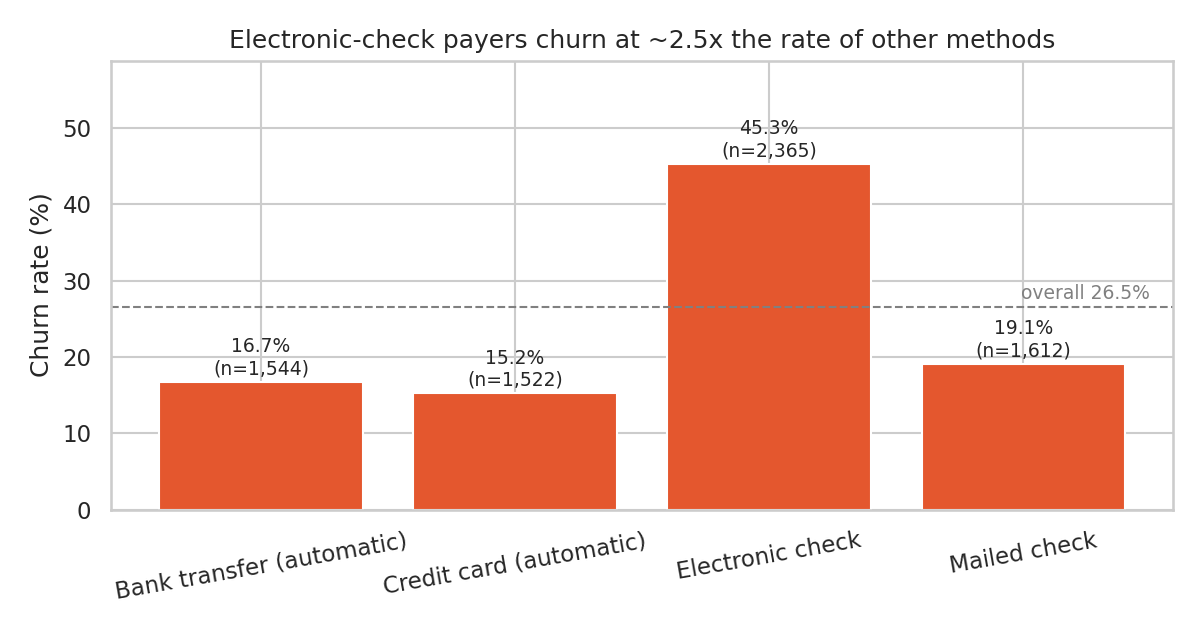

In [9]:
from IPython.display import Image; Image('../reports/figures/04_churn_by_payment.png')

**Takeaway:** electronic-check payers churn at **45.3% vs 15-19%** for every other method. Caveat: this is correlation. Electronic-check payers are also disproportionately month-to-month, so the payment effect is partly a contract effect (the modeling phase will separate them).

## 5. Tenure x contract interaction

In [10]:
eda.fig_heatmap(df)

Contract,Month-to-month,One year,Two year
tenure_bucket,,,
0-6,55.2,10.3,0.0
7-12,42.0,10.6,0.0
13-24,37.7,8.1,0.0
25-48,32.9,10.6,2.2
49+,26.0,12.9,3.3


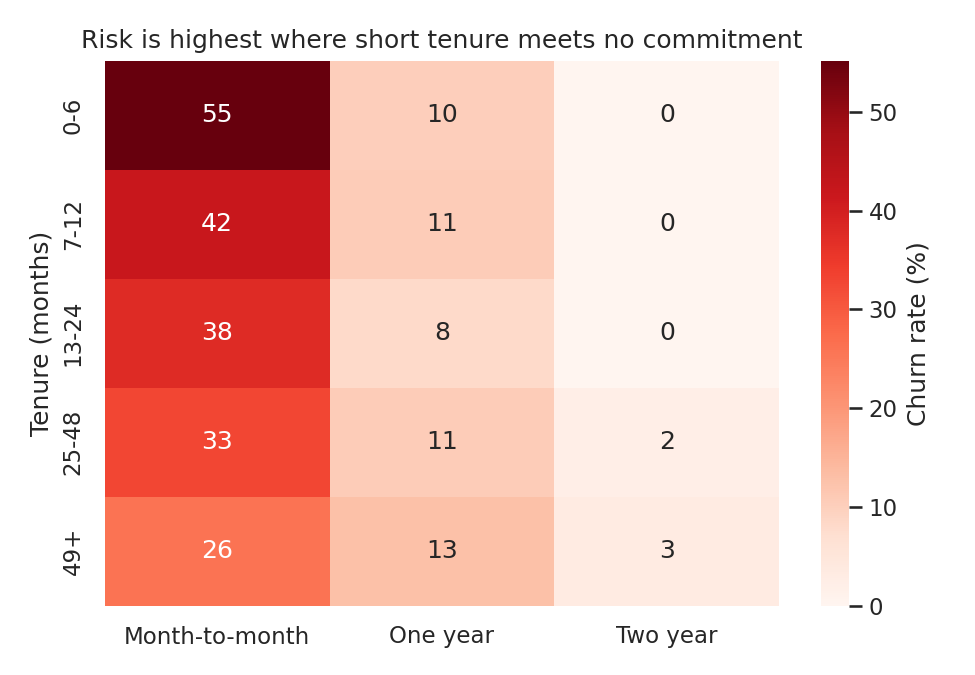

In [11]:
from IPython.display import Image; Image('../reports/figures/05_churn_heatmap_tenure_contract.png')

**Takeaway:** the worst cell is month-to-month in the first 6 months (**55%**). Two-year customers show 0% churn for the first 24 months because they cannot leave before the term ends, a structural artifact rather than loyalty. Note that month-to-month customers still churn at 26% even after 49 months, so tenure alone does not make them safe.

## 6. Protective add-ons

In [12]:
eda.fig_addons(df)

InternetService,DSL,Fiber optic
n_protective,,
0,42.7,63.6
1,26.6,46.8
2,13.2,32.4
3,6.7,19.7
4,3.2,8.4


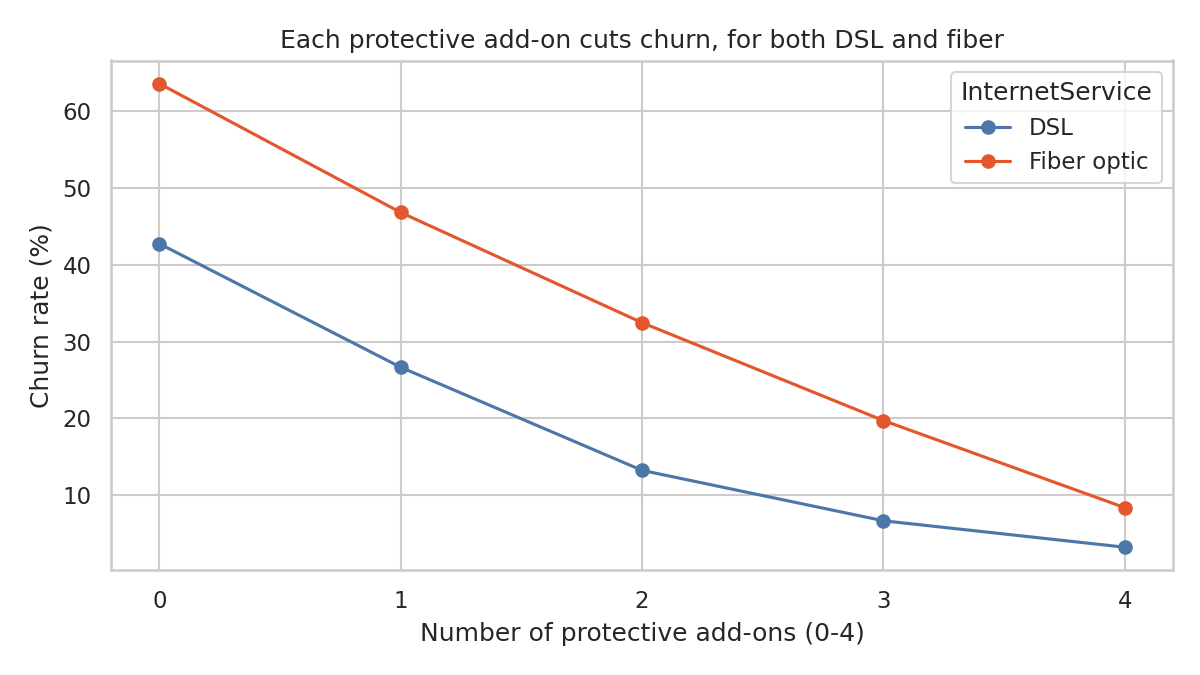

In [13]:
from IPython.display import Image; Image('../reports/figures/06_churn_by_addons.png')

**Takeaway:** churn falls steadily with each protective add-on (fiber: **63.6% with none to 8.4% with all four**). Fiber customers churn more at every add-on level, so the fiber premium is not the whole story. Bundling security/support into fiber plans is a testable retention play.

## 7. Candidate segments (informal, before clustering)
Four hand-built rules based on the charts above. Phase 4 will test whether unsupervised clustering rediscovers similar groups.

In [14]:
eda.segments(df)

,segment,customers,pct_of_base,churn_rate_pct,avg_monthly_charge,share_of_all_churners_pct
0,"A: new, month-to-month, fiber",916,13.0,70.2,82.08,34.4
1,"B: month-to-month, e-check, any tenure",1850,26.3,53.7,74.99,53.2
2,"C: committed, long-tenure (1-2yr, 25+ mo)",2689,38.2,6.9,67.14,9.9
3,D: no internet service,1526,21.7,7.4,21.08,6.0


**Takeaways:**
- **Segment A** (new, month-to-month, fiber): 13% of customers but **34% of all churners**, at a 70% churn rate. This is the priority target.
- **Segment B** (month-to-month, e-check) overlaps heavily with A but is broader: 26% of customers and **53% of all churners**.
- **Segment C** (committed, long-tenure) is the safe core: 38% of customers, 6.9% churn, only 9.9% of churners.
- **Segment D** (no internet) is low-value ($21/mo) and low-risk, so it needs no retention spend.

Segments overlap, so these are exploration tools, not a partition. Phase 4 builds a proper partition.